In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/mock")

products = pd.read_csv(DATA_DIR / "products.csv")
preferences = pd.read_csv(DATA_DIR / "user_preferences.csv")
c1 = pd.read_csv(DATA_DIR / "c1_product_aspects.csv")
c3 = pd.read_csv(DATA_DIR / "c3_temporal_features.csv")

print("Data loaded successfully.")

Data loaded successfully.


In [2]:
features = c1.merge(
    c3,
    on=["product_id", "aspect"],
    how="inner"
)

features["nominal_aspect_score"] = (
    features["aspect_quality"]
    + features["recent_quality"]
) / 2

display(features.head())

,product_id,aspect,aspect_quality,sentiment_score,c1_confidence,recent_quality,trend_score,temporal_uncertainty,emerging_issue_score,nominal_aspect_score
0,P001,battery,0.90,0.84,0.91,0.88,0.04,0.08,0.05,0.890
1,P001,camera,0.74,0.68,0.88,0.73,0.01,0.10,0.07,0.735
2,P001,performance,0.91,0.86,0.93,0.90,0.03,0.07,0.04,0.905
3,P001,display,0.82,0.78,0.89,0.81,0.01,0.09,0.05,0.815
4,P001,durability,0.79,0.72,0.84,0.78,0.00,0.12,0.08,0.785


In [3]:
pref = preferences[
    ["aspect", "importance"]
].copy()

pref["importance_weight"] = (
    pref["importance"]
    / pref["importance"].sum()
)

display(pref)

,aspect,importance,importance_weight
0,battery,5,0.238095
1,camera,3,0.142857
2,performance,4,0.190476
3,display,3,0.142857
4,durability,2,0.095238
5,price,4,0.190476


In [4]:
aspect_matrix = (
    features
    .pivot(
        index="product_id",
        columns="aspect",
        values="nominal_aspect_score"
    )
)

aspect_order = pref["aspect"].tolist()

aspect_matrix = aspect_matrix[
    aspect_order
]

display(aspect_matrix)

aspect,battery,camera,performance,display,durability,price
product_id,,,,,,
P001,0.890,0.735,0.905,0.815,0.785,0.695
P002,0.735,0.900,0.830,0.855,0.750,0.820
P003,0.850,0.870,0.925,0.895,0.825,0.575
P004,0.795,0.675,0.725,0.740,0.775,0.915
P005,0.875,0.785,0.815,0.795,0.905,0.775


In [5]:
max_budget = preferences["max_budget"].iloc[0]

eligible_products = products[
    products["price"] <= max_budget
]["product_id"]

X = aspect_matrix.loc[
    aspect_matrix.index.isin(eligible_products)
].copy()

display(X)

aspect,battery,camera,performance,display,durability,price
product_id,,,,,,
P001,0.890,0.735,0.905,0.815,0.785,0.695
P002,0.735,0.900,0.830,0.855,0.750,0.820
P004,0.795,0.675,0.725,0.740,0.775,0.915
P005,0.875,0.785,0.815,0.795,0.905,0.775


In [6]:
weights = (
    pref
    .set_index("aspect")
    .loc[aspect_order, "importance_weight"]
    .to_numpy()
)

def personalized_score(X_input):
    X_array = np.asarray(X_input)

    return np.dot(
        X_array,
        weights
    )

In [7]:
scores = personalized_score(X)

score_check = pd.DataFrame({
    "product_id": X.index,
    "personalized_score": scores
})

score_check = score_check.merge(
    products[
        ["product_id", "product_name"]
    ],
    on="product_id"
)

score_check = score_check.sort_values(
    "personalized_score",
    ascending=False
)

display(score_check)

,product_id,personalized_score,product_name
3,P005,0.823095,Phone E
0,P001,0.812857,Phone A
1,P002,0.811429,Phone B
2,P004,0.777619,Phone D


In [8]:
background = X.mean(
    axis=0
).to_frame().T

explainer = shap.Explainer(
    personalized_score,
    background
)

shap_values = explainer(X)

print("SHAP values calculated.")

ExactExplainer explainer: 5it [00:16,  4.13s/it]               

SHAP values calculated.


In [9]:
top_product_id = (
    score_check.iloc[0]["product_id"]
)

top_product_name = (
    score_check.iloc[0]["product_name"]
)

top_index = list(X.index).index(
    top_product_id
)

print(
    "Top product:",
    top_product_name,
    "(" + top_product_id + ")"
)

Top product: Phone E (P005)


In [10]:
top_explanation = pd.DataFrame({
    "aspect": aspect_order,
    "aspect_score": X.loc[
        top_product_id
    ].values,

    "importance_weight": weights,

    "shap_value": (
        shap_values.values[
            top_index
        ]
    )
})

top_explanation[
    "absolute_shap"
] = (
    top_explanation[
        "shap_value"
    ].abs()
)

top_explanation = (
    top_explanation
    .sort_values(
        "absolute_shap",
        ascending=False
    )
)

display(top_explanation)

,aspect,aspect_score,importance_weight,shap_value,absolute_shap
0,battery,0.875,0.238095,0.012202,0.012202
4,durability,0.905,0.095238,0.009643,0.009643
5,price,0.775,0.190476,-0.005000,0.005000
1,camera,0.785,0.142857,0.001607,0.001607
3,display,0.795,0.142857,-0.000893,0.000893
2,performance,0.815,0.190476,-0.000714,0.000714


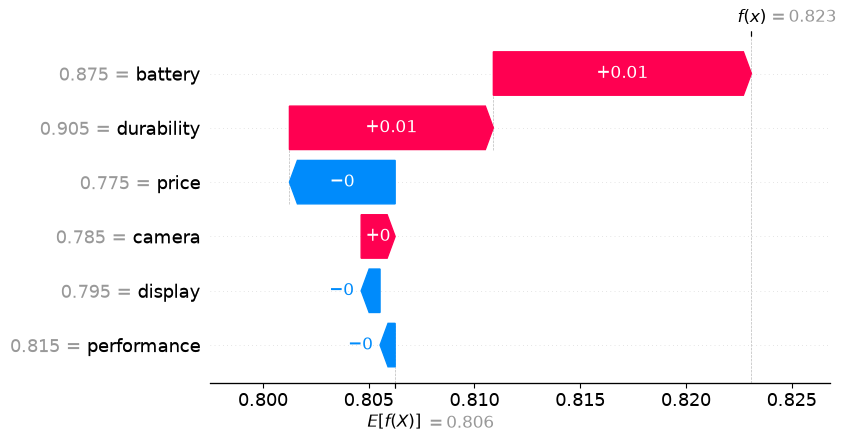

In [11]:
shap.plots.waterfall(
    shap_values[top_index],
    max_display=6
)

In [12]:
positive_reasons = (
    top_explanation[
        top_explanation["shap_value"] > 0
    ]
    .head(3)
)

display(positive_reasons)

,aspect,aspect_score,importance_weight,shap_value,absolute_shap
0,battery,0.875,0.238095,0.012202,0.012202
4,durability,0.905,0.095238,0.009643,0.009643
1,camera,0.785,0.142857,0.001607,0.001607


In [13]:
top_aspects = (
    positive_reasons["aspect"]
    .tolist()
)

if len(top_aspects) >= 2:
    explanation = (
        f"{top_product_name} ranks first mainly because "
        f"its {top_aspects[0]} and {top_aspects[1]} "
        f"features contribute positively to the user's priorities."
    )

elif len(top_aspects) == 1:
    explanation = (
        f"{top_product_name} ranks first mainly because "
        f"its {top_aspects[0]} feature contributes positively "
        f"to the user's priorities."
    )

else:
    explanation = (
        f"{top_product_name} ranks first based on its overall "
        f"personalized score."
    )

print(explanation)

Phone E ranks first mainly because its battery and durability features contribute positively to the user's priorities.


In [14]:
predicted_scores = personalized_score(X)

reconstructed_scores = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

assert np.allclose(
    predicted_scores,
    reconstructed_scores,
    atol=1e-6
)

print(
    "SHAP CONSISTENCY TEST: PASSED"
)

SHAP CONSISTENCY TEST: PASSED
